# Benchmarking Multilingual OpenCLIP / SigLIP2 for Local Image-Gallery Search

This notebook evaluates candidate vision–language models on **Crossmodal-3600** (36 languages) with a focus on:

- **Inference latency** after warm-up (image → vector and text → vector).
- **Memory footprint** (RAM and, if available, VRAM).
- **CPU utilisation** during encoding.
- **Retrieval quality** using Recall@K and NDCG@K.

The goal is to identify the model that gives the best trade-off between accuracy and resource consumption for **local, multilingual** gallery search.

## 1. Environment setup

Install the required packages if they are not already present.

In [1]:
# Uncomment and run once if needed
# !pip install -q open_clip_torch torch torchvision psutil tracemalloc datasets pandas matplotlib tqdm

In [2]:
import gc
import json
import os
import tarfile
import time
import tracemalloc
import urllib.request
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import psutil
import torch
from datasets import load_dataset
from open_clip import tokenizer
from PIL import Image
from tqdm import tqdm
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    torch.cuda.empty_cache()

Using device: cpu


## 2. Configuration

### 2.1 Candidate models

The list below covers the most relevant multilingual checkpoints.  
You can add any OpenCLIP-compatible model name (see `open_clip.list_pretrained()`).

| Model name (open_clip) | Family | Notes |
|---|---|---|
| `xlm-roberta-base-ViT-B-32` | OpenCLIP | Lightweight multilingual baseline (XLM-R base). |
| `XLM-Roberta-Large-ViT-H-14` | OpenCLIP | Strong multilingual retrieval, larger ViT-H backbone. |
| `ViT-B-16-SigLIP2__webli` | SigLIP2 | Small SigLIP2, good latency/accuracy trade-off. |
| `ViT-SO400M-16-SigLIP2-384__webli` | SigLIP2 | Larger SigLIP2, top accuracy in many multilingual benchmarks. |
| `nllb-clip-large-siglip__mrl` | OpenCLIP / SigLIP | NLLB text encoder + SigLIP vision, designed for many languages. |

> **Note**  
> SigLIP2 models are available through OpenCLIP’s model registry (e.g. `ViT-SO400M-16-SigLIP2-384__webli`).  
> If a checkpoint is not found, check `open_clip.list_pretrained()` for the exact tag.

In [3]:
open_clip.list_pretrained()

[('RN50', 'openai'),
 ('RN50', 'yfcc15m'),
 ('RN50', 'cc12m'),
 ('RN101', 'openai'),
 ('RN101', 'yfcc15m'),
 ('RN50x4', 'openai'),
 ('RN50x16', 'openai'),
 ('RN50x64', 'openai'),
 ('ViT-B-32', 'openai'),
 ('ViT-B-32', 'laion400m_e31'),
 ('ViT-B-32', 'laion400m_e32'),
 ('ViT-B-32', 'laion2b_e16'),
 ('ViT-B-32', 'laion2b_s34b_b79k'),
 ('ViT-B-32', 'datacomp_xl_s13b_b90k'),
 ('ViT-B-32', 'datacomp_m_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_clip_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_laion_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_image_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_text_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_basic_s128m_b4k'),
 ('ViT-B-32', 'commonpool_m_s128m_b4k'),
 ('ViT-B-32', 'datacomp_s_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_clip_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_laion_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_image_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_text_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_basic_s13m_b4k'),
 ('ViT-B-32', 'commonpool_s_s13m_b4k'),
 ('ViT-

In [4]:
MODELS_TO_BENCHMARK = [
    "xlm-roberta-base-ViT-B-32",
    "ViT-B-16-SigLIP2",
    "ViT-B-32-SigLIP2-256",
    "ViT-SO400M-16-SigLIP2-384",
    "nllb-clip-base-siglip",
]

# Latency measurement settings
WARMUP_RUNS = 3
MEASURED_RUNS = 20          # set to 100 as requested; reduce to 20 for a quick test
BATCH_SIZE_IMAGES = 8        # adjust according to available memory
BATCH_SIZE_TEXTS = 16

# Retrieval metric cutoff values
RECALL_KS = [1, 5, 10]
NDCG_K = 10

# Dataset language subset (set to None to use all 36 languages)
LANGUAGES = ["en", "ru"]   # e.g. ["en", "de", "fr", "es", "zh"]

N_IMAGES = 500

## 3. Load Crossmodal-3600

Crossmodal-3600 is hosted on Hugging Face.  
We keep the images as PIL objects (in memory) because the dataset is relatively small (3.6 k images).

If you already have the dataset locally, point `DATASET_CACHE` to the folder and skip the download.

In [5]:
DATASET_CACHE = os.path.expanduser("~/models/datasets/xm3600")
os.makedirs(DATASET_CACHE, exist_ok=True)

IMAGES_URL    = "https://open-images-dataset.s3.amazonaws.com/crossmodal-3600/images.tgz"
CAPTIONS_URL  = "https://google.github.io/crossmodal-3600/web-data/captions.zip"

IMAGES_TGZ     = os.path.join(DATASET_CACHE, "images.tgz")
CAPTIONS_ZIP   = os.path.join(DATASET_CACHE, "captions.zip")
CAPTIONS_JSONL = os.path.join(DATASET_CACHE, "captions.jsonl")
IMAGES_DIR     = os.path.join(DATASET_CACHE, "images")


def download(url: str, dest: str) -> None:
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        print(f"Already downloaded: {dest}")
        return
    print(f"Downloading {url}")
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp, open(dest, "wb") as f:
        total = int(resp.headers.get("Content-Length") or 0)
        with tqdm(
            total=total or None,
            unit="B",
            unit_scale=True,
            desc=os.path.basename(dest),
        ) as pbar:
            while True:
                chunk = resp.read(1 << 20)
                if not chunk:
                    break
                f.write(chunk)
                pbar.update(len(chunk))


def _find_jpg_dir(root: str) -> str | None:
    for dirpath, _, filenames in os.walk(root):
        if any(f.endswith(".jpg") for f in filenames):
            return dirpath
    return None


def extract_images() -> str:
    if os.path.isdir(IMAGES_DIR):
        d = _find_jpg_dir(IMAGES_DIR)
        if d is not None:
            print(f"Images already extracted: {d}")
            return d

    download(IMAGES_URL, IMAGES_TGZ)
    print("Extracting images …")
    os.makedirs(IMAGES_DIR, exist_ok=True)
    with tarfile.open(IMAGES_TGZ, "r:gz") as tar:
        tar.extractall(IMAGES_DIR)

    d = _find_jpg_dir(IMAGES_DIR)
    if d is None:
        raise RuntimeError(f"No .jpg files found under {IMAGES_DIR}")
    return d


def extract_captions() -> str:
    if os.path.exists(CAPTIONS_JSONL) and os.path.getsize(CAPTIONS_JSONL) > 0:
        print(f"Captions already extracted: {CAPTIONS_JSONL}")
        return CAPTIONS_JSONL

    download(CAPTIONS_URL, CAPTIONS_ZIP)
    print("Extracting captions …")
    with zipfile.ZipFile(CAPTIONS_ZIP) as zf:
        zf.extractall(DATASET_CACHE)

    if os.path.exists(CAPTIONS_JSONL):
        return CAPTIONS_JSONL

    for dirpath, _, filenames in os.walk(DATASET_CACHE):
        if "captions.jsonl" in filenames:
            found = os.path.join(dirpath, "captions.jsonl")
            os.replace(found, CAPTIONS_JSONL)
            return CAPTIONS_JSONL
    raise RuntimeError("captions.jsonl not found in archive")

# (Optional) per-language mapping, useful if you evaluate retrieval per language:
# caption_to_image_per_lang = {
#     lang: np.array(
#         [i for i, r in enumerate(rows) for _ in r.get(lang, {}).get("caption", [])]
#     )
#     for lang in all_langs
# }

In [6]:
images_dir     = extract_images()
captions_jsonl = extract_captions()

print("Loading captions …")
with open(captions_jsonl, "r", encoding="utf-8") as f:
    rows = [json.loads(line) for line in f if line.strip()]
rows = rows[:N_IMAGES]
print(f"Number of image records: {len(rows)}")

META_KEYS = {"image/key", "image/locale"}

# Collect language codes (order preserved from first record, union over all)
all_langs = []
_seen = set()
for row in rows:
    for k in row:
        if k not in META_KEYS and k not in _seen:
            all_langs.append(k)
            _seen.add(k)

if LANGUAGES is not None:
    all_langs = [l for l in all_langs if l in LANGUAGES]

texts_per_lang = {lang: [] for lang in all_langs}
for row in rows:
    for lang in all_langs:
        texts_per_lang[lang].extend(row.get(lang, {}).get("caption", []))

for lang in all_langs:
    print(f"  {lang}: {len(texts_per_lang[lang])} captions")

# Extract images in the same order as the caption records
print("Loading images …")
images = []
for row in tqdm(rows, desc="Collecting images"):
    key = row["image/key"]
    img_path = os.path.join(images_dir, f"{key}.jpg")
    images.append(Image.open(img_path).convert("RGB"))

print(f"Number of images: {len(images)}")

# Caption -> image index, with the original (image-major, then lang, then caption) order.
caption_to_image = []
for img_idx, row in enumerate(rows):
    for lang in all_langs:
        for _ in row.get(lang, {}).get("caption", []):
            caption_to_image.append(img_idx)
caption_to_image = np.array(caption_to_image)
caption_to_image

Images already extracted: /home/roflan/models/datasets/xm3600/images
Captions already extracted: /home/roflan/models/datasets/xm3600/captions.jsonl
Loading captions …
Number of image records: 500
  en: 1000 captions
  ru: 1000 captions
Loading images …


Number of images: 500


array([  0,   0,   0, ..., 499, 499, 499], shape=(2000,))

The dataset contains one row per image.  
Each row has an `image` field and a `captions` dictionary keyed by language code (e.g. `{"en": [...], "de": [...], ...}`).

We will create:

- `images`: list of PIL images.
- `texts_per_lang`: `{lang: [caption1, caption2, …]}` – we flatten all reference captions for each language so that every caption can serve as a query.

## 4. Benchmark utilities

### 4.1 Latency measurement

We use `time.perf_counter()` and synchronise CUDA when necessary.  
The function performs warm-up runs, then measures the average latency over `MEASURED_RUNS` calls.

In [7]:
def sync_if_cuda():
    if DEVICE == "cuda":
        torch.cuda.synchronize()


def measure_latency(fn, warmup=WARMUP_RUNS, runs=MEASURED_RUNS):
    """Return average latency in milliseconds."""
    # Warm-up
    for _ in range(warmup):
        fn()
    sync_if_cuda()

    # Timed runs
    sync_if_cuda()
    start = time.perf_counter()
    for _ in range(runs):
        fn()
    sync_if_cuda()
    end = time.perf_counter()

    return (end - start) / runs * 1000.0  # ms per call

### 4.2 Retrieval metrics

We compute **Recall@K** (K = 1, 5, 10) and **NDCG@10** for image-to-text retrieval.  
For each query caption, we rank all images by cosine similarity and check whether the ground-truth image appears in the top-K.

In [8]:
def compute_retrieval_metrics(image_embeds, text_embeds, caption_to_image, ks, ndcg_k=10):
    """
    image_embeds: (N_images, D) L2-normalised
    text_embeds:  (N_texts, D) L2-normalised
    caption_to_image: (N_texts,) ground-truth image index for each caption
    """
    # Similarity matrix (N_texts, N_images)
    sims = text_embeds @ image_embeds.T
    sims = sims.cpu().numpy()

    recalls = {k: 0.0 for k in ks}
    ndcg_sum = 0.0

    for i, gt_img in enumerate(caption_to_image):
        scores = sims[i]
        ranked = np.argsort(-scores)  # descending

        # Recall@K
        for k in ks:
            if gt_img in ranked[:k]:
                recalls[k] += 1

        # NDCG@K (binary relevance)
        dcg = 0.0
        for rank, idx in enumerate(ranked[:ndcg_k]):
            if idx == gt_img:
                dcg += 1.0 / np.log2(rank + 2)  # rank is 0-indexed
        # IDCG = 1 because only one relevant item
        ndcg_sum += dcg

    n = len(caption_to_image)
    recall_metrics = {f"Recall@{k}": recalls[k] / n for k in ks}
    ndcg_metrics = {f"NDCG@{ndcg_k}": ndcg_sum / n}
    return {**recall_metrics, **ndcg_metrics}

## 5. Model benchmarking loop

For every model we:

1. Load the checkpoint and pre-processing transforms.
2. Encode a fixed batch of images → measure image latency / memory / CPU.
3. Encode a fixed batch of texts → measure text latency / memory / CPU.
4. Encode the full dataset and compute retrieval metrics.

All measurements are performed after warm-up.

In [9]:
def encode_images(model, preprocess, images, batch_size=BATCH_SIZE_IMAGES):
    """Return L2-normalised image embeddings for a list of PIL images."""
    model.eval()
    all_embeds = []
    with torch.no_grad():
        for i in range(0, len(images), batch_size):
            batch = images[i : i + batch_size]
            tensors = torch.stack([preprocess(img) for img in batch]).to(DEVICE)
            embeds = model.encode_image(tensors)
            embeds = embeds / embeds.norm(dim=-1, keepdim=True)
            all_embeds.append(embeds.cpu())
    return torch.cat(all_embeds, dim=0)


def encode_texts(model, tokenizer_fn, texts, batch_size=BATCH_SIZE_TEXTS):
    """Return L2-normalised text embeddings for a list of strings."""
    model.eval()
    all_embeds = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch = texts[i : i + batch_size]
            tokens = tokenizer_fn(batch).to(DEVICE)
            embeds = model.encode_text(tokens)
            embeds = embeds / embeds.norm(dim=-1, keepdim=True)
            all_embeds.append(embeds.cpu())
    return torch.cat(all_embeds, dim=0)

In [ ]:
# Download models if not exist
for model_name in MODELS_TO_BENCHMARK:
    print(f"Model: {model_name}")
    try:
        model, _, preprocess = open_clip.create_model_and_transforms(
            model_name, require_pretrained=True, device=DEVICE, pretrained=next(x[1] for x in open_clip.list_pretrained() if x[0] == model_name)
        )
        model.eval()
        tokenizer_fn = open_clip.get_tokenizer(model_name)
    except Exception as e:  # noqa: BLE001
        print(f"  ⚠️  Could not load model: {e}")
        continue

In [10]:
results = []

# Pre-select a small batch for latency measurement (fixed for fairness)
latency_images = images[:BATCH_SIZE_IMAGES]

for model_name in tqdm(MODELS_TO_BENCHMARK, desc="Benchmarking models"):
    print(f"\n{'='*60}")
    print(f"Model: {model_name}")
    print('='*60)

    try:
        model, _, preprocess = open_clip.create_model_and_transforms(
            model_name, require_pretrained=True, device=DEVICE, pretrained=next(x[1] for x in open_clip.list_pretrained() if x[0] == model_name)
        )
        model.eval()
        tokenizer_fn = open_clip.get_tokenizer(model_name)
    except Exception as e:  # noqa: BLE001
        print(f"  ⚠️  Could not load model: {e}")
        continue

    # ------------------------------------------------------------------
    # 1. Latency – image encoding
    # ------------------------------------------------------------------
    def _encode_image_batch():
        tensors = torch.stack([preprocess(img) for img in latency_images]).to(DEVICE)
        with torch.no_grad():
            _ = model.encode_image(tensors)

    img_latency_ms = measure_latency(_encode_image_batch)

    # ------------------------------------------------------------------
    # 2. Latency – text encoding
    # ------------------------------------------------------------------
    sample_texts = texts_per_lang[all_langs[0]][:BATCH_SIZE_TEXTS]

    def _encode_text_batch():
        tokens = tokenizer_fn(sample_texts).to(DEVICE)
        with torch.no_grad():
            _ = model.encode_text(tokens)

    txt_latency_ms = measure_latency(_encode_text_batch)

    # ------------------------------------------------------------------
    # 3. Full-dataset retrieval metrics
    # ------------------------------------------------------------------
    print("  Encoding all images …")
    img_embeds = encode_images(model, preprocess, images)

    # For retrieval we use all captions from all selected languages
    all_texts = []
    for lang in all_langs:
        all_texts.extend(texts_per_lang[lang])

    print(f"  Encoding {len(all_texts)} texts …")
    txt_embeds = encode_texts(model, tokenizer_fn, all_texts)

    metrics = compute_retrieval_metrics(
        img_embeds, txt_embeds, caption_to_image, ks=RECALL_KS, ndcg_k=NDCG_K
    )

    # ------------------------------------------------------------------
    # Store results
    # ------------------------------------------------------------------
    results.append({
        "model": model_name,
        "img_latency_ms": img_latency_ms,
        "txt_latency_ms": txt_latency_ms,
        **metrics,
    })
    print(results)
    
    # Clean up to avoid memory leaks between models
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

print("\nBenchmark complete.")

Benchmarking models:   0%|          | 0/5 [00:00<?, ?it/s]


Model: xlm-roberta-base-ViT-B-32
  Encoding all images …
  Encoding 2000 texts …
[{'model': 'xlm-roberta-base-ViT-B-32', 'img_latency_ms': 120.94919115043012, 'txt_latency_ms': 310.28521485059173, 'Recall@1': 0.0025, 'Recall@5': 0.0105, 'Recall@10': 0.021, 'NDCG@10': np.float64(0.0094581401973508)}]

Model: ViT-B-16-SigLIP2
  Encoding all images …
  Encoding 2000 texts …
[{'model': 'xlm-roberta-base-ViT-B-32', 'img_latency_ms': 120.94919115043012, 'txt_latency_ms': 310.28521485059173, 'Recall@1': 0.0025, 'Recall@5': 0.0105, 'Recall@10': 0.021, 'NDCG@10': np.float64(0.0094581401973508)}, {'model': 'ViT-B-16-SigLIP2', 'img_latency_ms': 452.71399804987595, 'txt_latency_ms': 269.35659459995804, 'Recall@1': 0.002, 'Recall@5': 0.008, 'Recall@10': 0.021, 'NDCG@10': np.float64(0.008920634290415867)}]

Model: ViT-B-32-SigLIP2-256
  Encoding all images …
  Encoding 2000 texts …
[{'model': 'xlm-roberta-base-ViT-B-32', 'img_latency_ms': 120.94919115043012, 'txt_latency_ms': 310.28521485059173, 'R

In [11]:
results

[{'model': 'xlm-roberta-base-ViT-B-32',
  'img_latency_ms': 120.94919115043012,
  'txt_latency_ms': 310.28521485059173,
  'Recall@1': 0.0025,
  'Recall@5': 0.0105,
  'Recall@10': 0.021,
  'NDCG@10': np.float64(0.0094581401973508)},
 {'model': 'ViT-B-16-SigLIP2',
  'img_latency_ms': 452.71399804987595,
  'txt_latency_ms': 269.35659459995804,
  'Recall@1': 0.002,
  'Recall@5': 0.008,
  'Recall@10': 0.021,
  'NDCG@10': np.float64(0.008920634290415867)},
 {'model': 'ViT-B-32-SigLIP2-256',
  'img_latency_ms': 164.5355151500553,
  'txt_latency_ms': 271.34894215050736,
  'Recall@1': 0.002,
  'Recall@5': 0.008,
  'Recall@10': 0.0215,
  'NDCG@10': np.float64(0.009040818382092728)},
 {'model': 'ViT-SO400M-16-SigLIP2-384',
  'img_latency_ms': 6340.739121750084,
  'txt_latency_ms': 1211.8048144002387,
  'Recall@1': 0.002,
  'Recall@5': 0.012,
  'Recall@10': 0.0245,
  'NDCG@10': np.float64(0.010510443828446618)},
 {'model': 'nllb-clip-base-siglip',
  'img_latency_ms': 1407.6623134496913,
  'txt_lat

## 6. Results

The table below summarises all measurements.  
Lower latency and memory are better; higher Recall/NDCG are better.

In [12]:
df = pd.DataFrame(results)
df = df.sort_values("Recall@1", ascending=False).reset_index(drop=True)

# Reorder columns for readability
cols = [
    "model",
    "img_latency_ms", "txt_latency_ms",
    "img_cpu_percent", "txt_cpu_percent",
    "py_peak_img_mib", "cuda_peak_img_mib",
    "py_peak_txt_mib", "cuda_peak_txt_mib",
    "Recall@1", "Recall@5", "Recall@10", "NDCG@10",
]
df = df[[c for c in cols if c in df.columns]]
df

,model,img_latency_ms,txt_latency_ms,Recall@1,Recall@5,Recall@10,NDCG@10
0,xlm-roberta-base-ViT-B-32,120.949191,310.285215,0.0025,0.0105,0.0210,0.009458
1,ViT-B-16-SigLIP2,452.713998,269.356595,0.0020,0.0080,0.0210,0.008921
2,ViT-B-32-SigLIP2-256,164.535515,271.348942,0.0020,0.0080,0.0215,0.009041
3,ViT-SO400M-16-SigLIP2-384,6340.739122,1211.804814,0.0020,0.0120,0.0245,0.010510
4,nllb-clip-base-siglip,1407.662313,561.372797,0.0020,0.0085,0.0205,0.008994


### 6.1 Trade-off visualisation

Scatter plot of **Recall@1 vs. image latency** helps identify the Pareto-optimal model for a local gallery.

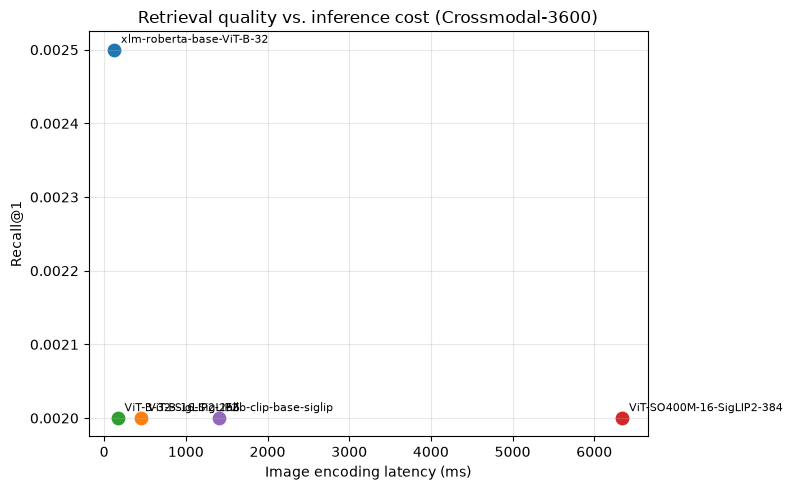

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in df.iterrows():
    ax.scatter(row["img_latency_ms"], row["Recall@1"], s=80, label=row["model"])
    ax.annotate(row["model"], (row["img_latency_ms"], row["Recall@1"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Image encoding latency (ms)")
ax.set_ylabel("Recall@1")
ax.set_title("Retrieval quality vs. inference cost (Crossmodal-3600)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

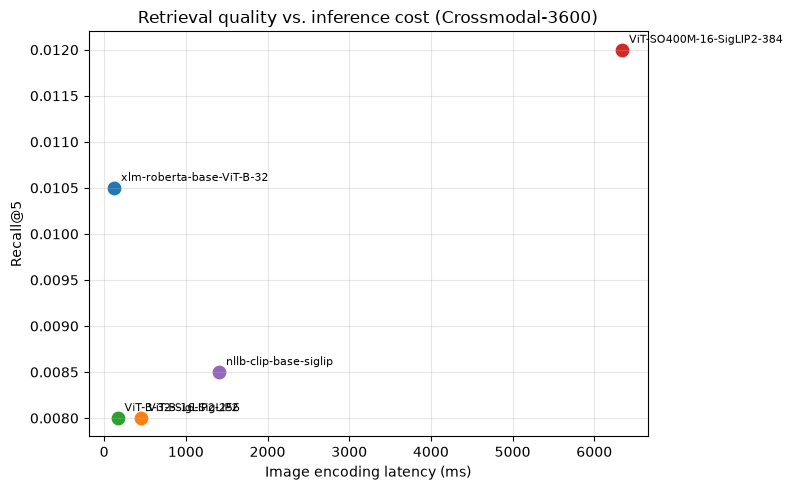

In [22]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in df.iterrows():
    ax.scatter(row["img_latency_ms"], row["Recall@5"], s=80, label=row["model"])
    ax.annotate(row["model"], (row["img_latency_ms"], row["Recall@5"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Image encoding latency (ms)")
ax.set_ylabel("Recall@5")
ax.set_title("Retrieval quality vs. inference cost (Crossmodal-3600)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

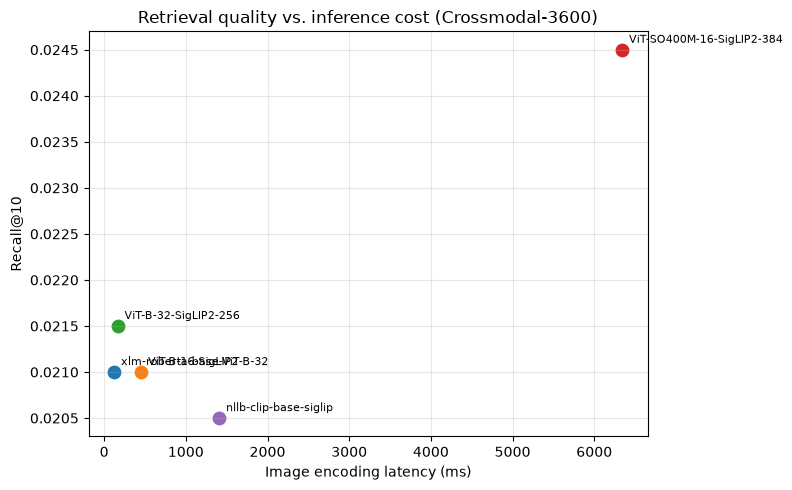

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in df.iterrows():
    ax.scatter(row["img_latency_ms"], row["Recall@10"], s=80, label=row["model"])
    ax.annotate(row["model"], (row["img_latency_ms"], row["Recall@10"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Image encoding latency (ms)")
ax.set_ylabel("Recall@10")
ax.set_title("Retrieval quality vs. inference cost (Crossmodal-3600)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

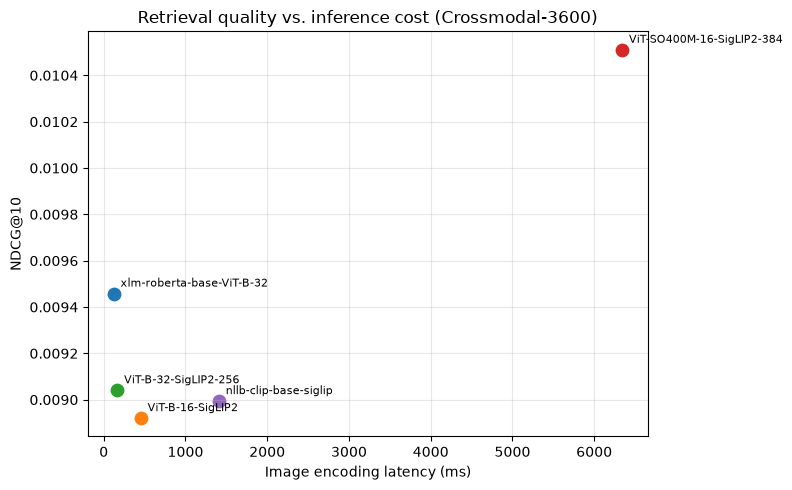

In [21]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in df.iterrows():
    ax.scatter(row["img_latency_ms"], row["NDCG@10"], s=80, label=row["model"])
    ax.annotate(row["model"], (row["img_latency_ms"], row["NDCG@10"]),
                textcoords="offset points", xytext=(5, 5), fontsize=8)

ax.set_xlabel("Image encoding latency (ms)")
ax.set_ylabel("NDCG@10")
ax.set_title("Retrieval quality vs. inference cost (Crossmodal-3600)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6.2 Recommended model for local gallery search

Interpret the table according to your hardware constraints:

- **If latency is critical** (e.g. real-time search on CPU), look at the lowest `img_latency_ms` with acceptable `Recall@1` – often a smaller SigLIP2 or `xlm-roberta-base-ViT-B-32`.
- **If accuracy is paramount** and you can tolerate higher latency/memory, `ViT-SO400M-16-SigLIP2-384__webli` or `XLM-Roberta-Large-ViT-H-14` usually lead on multilingual retrieval.
- **For a balanced choice**, `ViT-B-16-SigLIP2__webli` frequently offers a strong trade-off.

> **Important**  
> The numbers above are measured on the current machine.  
> Run the notebook on your target hardware (especially if it is CPU-only) to obtain representative latency and memory figures.

## 7. Export results

Save the benchmark table as CSV for later comparison.

In [19]:
df.to_csv("clip_benchmark_results.csv", index=False)
print("Results saved to clip_benchmark_results.csv")

Results saved to clip_benchmark_results.csv
